# Where should a new shopping mall go? Segmenting Los Angeles County cities with clustering

**Capstone project - IBM Applied Data Science style.** Maximize profit for a shopping-mall business by segmenting locations using clustering on coordinates and surrounding-venue data.

**Pipeline**
1. Scrape the cities of Los Angeles County (name, population) from Wikipedia
2. Pull each city's coordinates from the Wikipedia API (geo tags on each city page)
3. Count nearby venues by category around each city centre (OpenStreetMap / Overpass API)
4. Cluster cities with K-Means (k picked by silhouette score) to find commercial "segments"
5. Map the segments with Folium
6. Rank candidate cities for a new mall: big population, thriving commercial activity, **no mall nearby**

> **Note on the venue source.** The original course uses the Foursquare API, which needs a personal API key (and Foursquare has since changed its API). This notebook uses OpenStreetMap through the free Overpass API instead, so it runs with no credentials. If the live Overpass call is rate-limited, the notebook automatically falls back to the saved snapshot in `data/` of this repo (collected October 2026).

## 1. Business problem
A mall developer wants to open one new mall in Los Angeles County. A mall earns the most where **many people live**, **shopping, dining and entertainment already cluster** (foot traffic and spending habits exist), and **no mall competes within a short drive**. Clustering groups cities into commercial profiles, so we can compare like with like and spot the under-served ones.

In [1]:
import re, time, requests, numpy as np, pandas as pd
from io import StringIO
import matplotlib.pyplot as plt
import folium
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
HEADERS = {'User-Agent': 'mall-capstone/1.0 (student project)'}
RADIUS_M = 2500      # venue search radius around each city centre
TOP_N = 30           # number of largest cities to analyse

## 2. Scrape Wikipedia: cities of Los Angeles County
We read the list table straight from the Wikipedia page, clean it, and keep the largest cities by 2020 census population.

In [2]:
url = 'https://en.wikipedia.org/wiki/List_of_cities_in_Los_Angeles_County,_California'
html = requests.get(url, headers=HEADERS, timeout=30).text
cities = pd.read_html(StringIO(html))[0]
cities.columns = ['city', 'incorporated', 'population']
cities = cities.dropna(subset=['population']).copy()
cities['city'] = cities['city'].str.replace(r'\[.*?\]', '', regex=True).str.strip()
cities['population'] = cities['population'].astype(float).astype(int)
cities = cities.sort_values('population', ascending=False).head(TOP_N).reset_index(drop=True)
print(cities.shape)
cities.head(10)

(30, 3)


            city       incorporated  population
0    Los Angeles      April 4, 1850     3898747
1     Long Beach  December 13, 1897      466742
2  Santa Clarita  December 15, 1987      228673
3       Glendale  February 15, 1906      196543
4      Lancaster  November 22, 1977      173516
5       Palmdale    August 24, 1962      169450
6         Pomona    January 6, 1888      151713
7       Torrance       May 12, 1921      147067
8       Pasadena      June 19, 1886      138699
9         Downey  December 17, 1956      114355

## 3. Coordinates from Wikipedia
Every city page carries geo coordinates; the MediaWiki API returns them for a batch of page titles.

In [3]:
def wiki_coords(names):
    titles = {c: ('Los Angeles' if c == 'Los Angeles' else f'{c}, California') for c in names}
    out = {}
    for i in range(0, len(names), 20):
        chunk = names[i:i+20]
        r = requests.get('https://en.wikipedia.org/w/api.php', headers=HEADERS, params=dict(
            action='query', prop='coordinates', titles='|'.join(titles[c] for c in chunk),
            format='json', redirects=1, colimit=50)).json()['query']
        norm = {n['from']: n['to'] for n in r.get('normalized', [])}
        red = {n['from']: n['to'] for n in r.get('redirects', [])}
        got = {p['title']: p['coordinates'][0] for p in r['pages'].values() if 'coordinates' in p}
        for c in chunk:
            t = titles[c]; t = norm.get(t, t); t = red.get(t, t)
            if t in got: out[c] = (got[t]['lat'], got[t]['lon'])
    return out

co = wiki_coords(list(cities.city))
cities['lat'] = cities.city.map(lambda c: co.get(c, (np.nan, np.nan))[0])
cities['lon'] = cities.city.map(lambda c: co.get(c, (np.nan, np.nan))[1])
print('missing coordinates:', list(cities[cities.lat.isna()].city))
cities = cities.dropna(subset=['lat']).reset_index(drop=True)
cities.head()

missing coordinates: ['Baldwin Park']


            city       incorporated  population        lat         lon
0    Los Angeles      April 4, 1850     3898747  34.050000 -118.250000
1     Long Beach  December 13, 1897      466742  33.768333 -118.195556
2  Santa Clarita  December 15, 1987      228673  34.420000 -118.520000
3       Glendale  February 15, 1906      196543  34.146111 -118.255000
4      Lancaster  November 22, 1977      173516  34.683333 -118.150000

## 4. Venue data around each city
For each city centre we count venues within 2.5 km in seven categories: **malls, other retail, grocery, food and drink, entertainment, services, education**. This is the same idea as the Foursquare `explore` call (venues around a lat/lng), using OpenStreetMap tags.

In [4]:
CATS = {
 'mall': '[shop=mall]',
 'retail_other': '[shop~"clothes|shoes|department_store|electronics|jewelry|sports|gift|beauty|fashion_accessories"]',
 'grocery': '[shop~"supermarket|convenience|greengrocer"]',
 'food': '[amenity~"restaurant|cafe|fast_food|bar|pub"]',
 'entertainment': '[amenity~"cinema|theatre|arts_centre|nightclub"]',
 'services': '[amenity~"bank|pharmacy|clinic|doctors"]',
 'education': '[amenity~"school|college|university"]',
}
SNAPSHOT = 'https://raw.githubusercontent.com/NeelanjanaPramod/mall-location-clustering/main/data/venue_counts.csv'

def overpass_counts(lat, lon, r=RADIUS_M, tries=4):
    q = f'[out:json][timeout:90];(nwr(around:{r},{lat},{lon})[shop];nwr(around:{r},{lat},{lon})[amenity];)->.a;'
    for f in CATS.values():
        q += f'nwr.a{f};out count;'
    for k in range(tries):
        resp = requests.post('https://overpass-api.de/api/interpreter', data={'data': q}, headers=HEADERS, timeout=120)
        if resp.status_code == 200:
            v = [int(e['tags']['total']) for e in resp.json()['elements']]
            if len(v) == len(CATS):
                return dict(zip(CATS, v))
        time.sleep(15 * (k + 1))
    return None

LIVE = False   # set True to re-query OpenStreetMap live (about 15-30 s per city); False loads the saved snapshot
if LIVE:
    rows = []
    for _, r in cities.iterrows():
        c = overpass_counts(r.lat, r.lon)
        if c is None: print('skipped', r.city); continue
        rows.append(dict(city=r.city, **c)); time.sleep(5)
    venues = pd.DataFrame(rows)
else:
    venues = pd.read_csv(SNAPSHOT)
df = cities.merge(venues, on='city', how='inner')
print(df.shape)
df.head()

(29, 12)


            city       incorporated  population        lat         lon  mall  \
0    Los Angeles      April 4, 1850     3898747  34.050000 -118.250000    10   
1     Long Beach  December 13, 1897      466742  33.768333 -118.195556     0   
2  Santa Clarita  December 15, 1987      228673  34.420000 -118.520000     0   
3       Glendale  February 15, 1906      196543  34.146111 -118.255000     4   
4      Lancaster  November 22, 1977      173516  34.683333 -118.150000     1   

   retail_other  grocery  food  entertainment  services  education  
0           128       42   635             41        60         51  
1            23       41   190             10        23         13  
2             9        7    36              1         9          8  
3            45       32   194             10        42         29  
4            17       22    96              3        27         18  

## 5. Feature engineering
Venue counts are heavily skewed (Los Angeles proper has far more of everything), so we use `log1p` and standardise. Population enters as a log too. Coordinates are **not** used as features, because we want to group cities by commercial profile, not by who is next to whom; we use them for mapping.

In [5]:
feat_cols = list(CATS) + ['population']
X = np.log1p(df[feat_cols].astype(float))
Xs = StandardScaler().fit_transform(X)
pd.DataFrame(Xs, columns=feat_cols).describe().round(2).loc[['mean', 'std']]

      mall  retail_other  grocery  food  entertainment  services  education  \
mean  0.00         -0.00     0.00  0.00           0.00      0.00      -0.00   
std   1.02          1.02     1.02  1.02           1.02      1.02       1.02   

      population  
mean       -0.00  
std         1.02  

## 6. K-Means clustering
We pick k with the silhouette score (and eyeball the elbow).

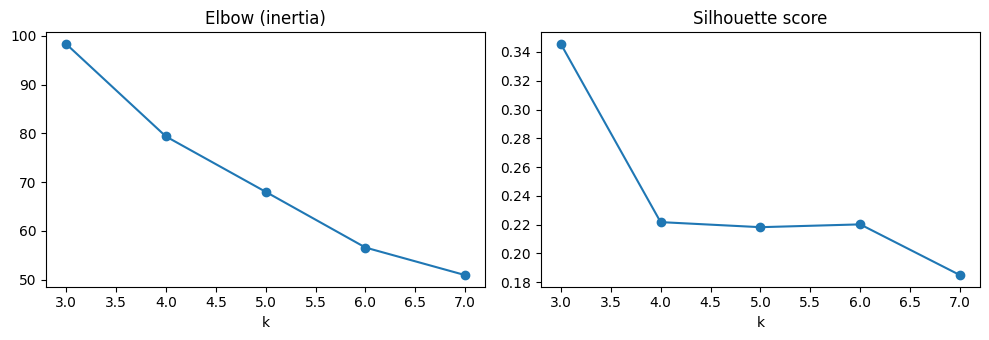

best k by silhouette: 3 0.346


In [6]:
ks = range(3, 8)   # at least 3 segments so the grouping is useful
sil, inertia = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xs)
    sil.append(silhouette_score(Xs, km.labels_)); inertia.append(km.inertia_)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(list(ks), inertia, 'o-'); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(list(ks), sil, 'o-'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()
best_k = list(ks)[int(np.argmax(sil))]
print('best k by silhouette:', best_k, round(max(sil), 3))

In [7]:
km = KMeans(n_clusters=best_k, n_init=20, random_state=42).fit(Xs)
df['cluster'] = km.labels_
profile = df.groupby('cluster')[feat_cols].mean().round(0).astype(int)
profile['n_cities'] = df.groupby('cluster').size()
profile['cities'] = df.groupby('cluster')['city'].apply(lambda s: ', '.join(s))
profile

         mall  retail_other  grocery  food  entertainment  services  \
cluster                                                               
0           1            10       13    54              1         9   
1           1            61       28   208              8        42   
2          10           128       42   635             41        60   

         education  population  n_cities  \
cluster                                    
0               23      104177        17   
1               30      152207        11   
2               51     3898747         1   

                                                    cities  
cluster                                                     
0        Santa Clarita, Palmdale, Pomona, West Covina, ...  
1        Long Beach, Glendale, Lancaster, Torrance, Pas...  
2                                              Los Angeles  

## 7. Map the segments (Folium)

In [8]:
palette = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 'cadetblue']
m = folium.Map(location=[df.lat.mean(), df.lon.mean()], zoom_start=9, tiles='OpenStreetMap')
for _, r in df.iterrows():
    folium.CircleMarker([r.lat, r.lon], radius=5 + r.population / 150000, color=palette[r.cluster],
        fill=True, fill_opacity=0.7,
        popup=folium.Popup(f"<b>{r.city}</b><br>cluster {r.cluster}<br>pop {r.population:,}<br>malls within {RADIUS_M/1000} km: {r.mall}", max_width=250)).add_to(m)
m.save('la_county_clusters.html')
m

<folium.Map - interactive map; re-run the cell to render>

## 8. Candidate locations for a new mall
Score each city on **demand** (population and commercial activity) and filter to cities with **no mall within 2.5 km of the centre**.

`activity = retail_other + food + entertainment` (the venues that tell us people already go out and spend). `score = percentile(population) + percentile(activity)`, restricted to `mall == 0`.

In [9]:
df['activity'] = df.retail_other + df.food + df.entertainment
df['score'] = df.population.rank(pct=True) + df.activity.rank(pct=True)
cand = df[df.mall == 0].sort_values('score', ascending=False)
cand[['city', 'population', 'activity', 'mall', 'cluster', 'score']].head(10).round(2)

             city  population  activity  mall  cluster  score
1      Long Beach      466742       223     0        1   1.69
13        Burbank      107337       309     0        1   1.41
2   Santa Clarita      228673        46     0        0   1.17
24  Redondo Beach       71576       343     0        1   1.07
18     South Gate       92726       121     0        0   1.00
12      Inglewood      107762        76     0        0   0.97
6          Pomona      151713        27     0        0   0.84
11       El Monte      109450        35     0        0   0.76
23     Bellflower       79190       113     0        0   0.72
14        Norwalk      102773        41     0        0   0.72

In [10]:
top = cand.head(5)
m2 = folium.Map(location=[df.lat.mean(), df.lon.mean()], zoom_start=9, tiles='OpenStreetMap')
for _, r in df[df.mall > 0].iterrows():
    folium.CircleMarker([r.lat, r.lon], radius=5, color='gray', fill=True, fill_opacity=0.5,
                        popup=f"{r.city}: existing mall(s) nearby ({r.mall})").add_to(m2)
for i, (_, r) in enumerate(top.iterrows(), 1):
    folium.Marker([r.lat, r.lon], popup=f"#{i} {r.city} (pop {r.population:,})",
                  icon=folium.Icon(color='green', icon='shopping-cart', prefix='fa')).add_to(m2)
m2.save('mall_candidates.html')
m2

<folium.Map - interactive map; re-run the cell to render>

## 9. Conclusions

**Segments (K-Means, k=3 by silhouette score 0.35)**
- **Cluster 2 - Los Angeles itself.** A one-city segment: roughly 3x the dining and 2x the retail activity of any other city, plus 10 malls in the search radius. It is saturated, not a target.
- **Cluster 1 - established commercial hubs** (Long Beach, Glendale, Torrance, Pasadena, Burbank, Redondo Beach and others). Mid-sized populations with dense retail, food and entertainment.
- **Cluster 0 - residential, lighter commercial** (Santa Clarita, Palmdale, Pomona, West Covina and others). Plenty of people, thin retail and entertainment.

**Where to look for a new mall (population and activity score, no mall within 2.5 km of the centre)**
1. **Long Beach** - second-largest city in the county (about 467k people) with a hub-level commercial profile and no mall tagged near its centre.
2. **Burbank** and **Redondo Beach** - small populations but some of the densest retail/food/entertainment activity, which suggests demand from visitors and commuters.
3. **Santa Clarita** - about 229k people, light commercial activity, an under-served suburban market.

**Limitations (read before quoting the numbers)**
- Venue counts come from OpenStreetMap, which is community-edited, so coverage and tagging vary by city. A city showing zero malls may have one that is untagged or sits outside the 2.5 km circle around the city-centre coordinate.
- One search circle around each city centre is a rough proxy for a whole city. Large cities such as Long Beach and Los Angeles span much more than 2.5 km.
- Population is a demand proxy. Income, traffic, rents and land cost would be the next features to add.
- The silhouette score (0.35) is moderate, and Los Angeles forms its own cluster. Treat the segments as a screening tool, not a final siting decision.
- Baldwin Park had no coordinates on its Wikipedia page, so it is dropped (29 of the top 30 cities analysed).

**Next steps:** add household income (Census API), drive-time catchments instead of circles, and a profit model per candidate site.
